# Induced fit with different signals for the two complexes: multi-cycle kinetics (MCK)

Parameter-recovery benchmark. This notebook is AI generated, and has been reviewed by Osvaldo Burastero.

The data are simulated from the rate equations written below, integrated with SciPy (`solve_ivp`, Radau). No pykingenie function is used to make the data. The data are then fitted with pykingenie, using one Smax (Rmax) shared by all curves, and the fitted parameters are compared with the true ones. A parameter counts as recovered when its relative error is at most 5%.

Gaussian noise with a standard deviation of 0.5 RU is added, 1% of Rmax (50 RU). This is at the high end of real instruments: reference-subtracted SPR data typically show 0.1-0.5 RU of noise, and BLI 0.3-1% of a typical binding signal.


## Model

Same model as the induced fit, but the induced complex $AL$ gives `ratio` times the signal of $AL_{int}$ (for example after a change of conformation or hydration):

$$\frac{dx_1}{dt} = k_{on}\,C\,(R_{max} - x_1 - x_2) - k_{off}\,x_1 - k_c\,x_1 + k_{rev}\,x_2$$

$$\frac{dx_2}{dt} = k_c\,x_1 - k_{rev}\,x_2, \qquad \text{signal} = x_1 + \text{ratio}\cdot x_2$$

$R_{max}$ is the signal of the surface fully occupied by $AL_{int}$.

pykingenie reports `k_on [1/(s*µM)]`, `k_off [1/s]`, `k_c [1/s]`, `k_rev [1/s]`, the signal ratio and `Smax` (= $R_{max}$).

In [1]:
import sys

import numpy as np

sys.path.insert(0, '..')
from benchmark_helpers import simulate_mck, compare_parameters, plot_fit
from pykingenie.fitter_surface import KineticsFitter

## True parameters and experiment design

Each concentration is injected on a regenerated (free) surface for 300 s, followed by 600 s of buffer. Sampling every 1 s.

In [2]:
params = dict(kon=1.0, koff=0.05, kc=0.01, krev=0.002, Rmax=50.0, ratio=1.5)
concs = [0.0031, 0.0093, 0.028, 0.083, 0.25, 0.75]  # µM; overall Kd = 0.0083 µM

true_values = {'k_on': params['kon'], 'k_off': params['koff'], 'k_c': params['kc'], 'k_rev': params['krev'],
               'signal_ratio': params['ratio'], 'Smax': params['Rmax']}

## Rate equations (first principles)

In [3]:
def rhs(t, y, conc, p):
    x1, x2 = y
    dx1 = p['kon'] * conc * (p['Rmax'] - x1 - x2) - p['koff'] * x1 - p['kc'] * x1 + p['krev'] * x2
    dx2 = p['kc'] * x1 - p['krev'] * x2
    return [dx1, dx2]


def signal(y, p):
    return y[:, 0] + p['ratio'] * y[:, 1]


y0 = [0.0, 0.0]

## Simulate the data

In [4]:
data = simulate_mck(rhs, signal, y0, params, concs, assoc_time=300.0, disso_time=600.0, dt=1.0,
                    noise_sd=0.5, seed=0)

## Fit with pykingenie

One Smax shared by all curves (`smax_id` is 0 for every curve).

In [5]:
fitter = KineticsFitter(
    time_assoc_lst=data['time_assoc'], association_signal_lst=data['assoc'],
    lig_conc_lst=concs,
    time_diss_lst=data['time_disso'], dissociation_signal_lst=data['disso'],
    smax_id=[0] * len(concs), name_lst=['benchmark'], is_single_cycle=False,
)
fitter.get_steady_state()
fitter.fit_steady_state()  # starting value of Kd
fitter.fit_one_site_if_assoc_and_disso(shared_smax=True, fit_signal_ratio=True)
fitter.fit_params_kinetics

,k_on [1/(s*µM)],k_off [1/s],k_c [1/s],k_rev [1/s],Signal ratio (AL/ALint),Smax
0,1.014409,0.05121,0.010069,0.001998,1.504297,49.887561


## Compare with the true parameters

In [6]:
fitted_values = {'k_on': fitter.k_on, 'k_off': fitter.k_off, 'k_c': fitter.k_c, 'k_rev': fitter.k_rev,
                 'signal_ratio': fitter.signal_ratio, 'Smax': fitter.Smax[0]}

comparison = compare_parameters(true_values, fitted_values, rtol=0.05)
worst = comparison['rel. error (%)'].abs().idxmax()
print(f"All parameters recovered within 5%: {comparison['recovered'].all()}. "
      f"Largest error: {comparison.loc[worst, 'rel. error (%)']:+.2f}% ({worst})")
comparison

All parameters recovered within 5%: True. Largest error: +2.42% (k_off)


,true,fitted,rel. error (%),recovered
parameter,,,,
k_on,1.000,1.014409,1.440874,True
k_off,0.050,0.051210,2.420080,True
k_c,0.010,0.010069,0.687780,True
k_rev,0.002,0.001998,-0.108758,True
signal_ratio,1.500,1.504297,0.286498,True
Smax,50.000,49.887561,-0.224878,True


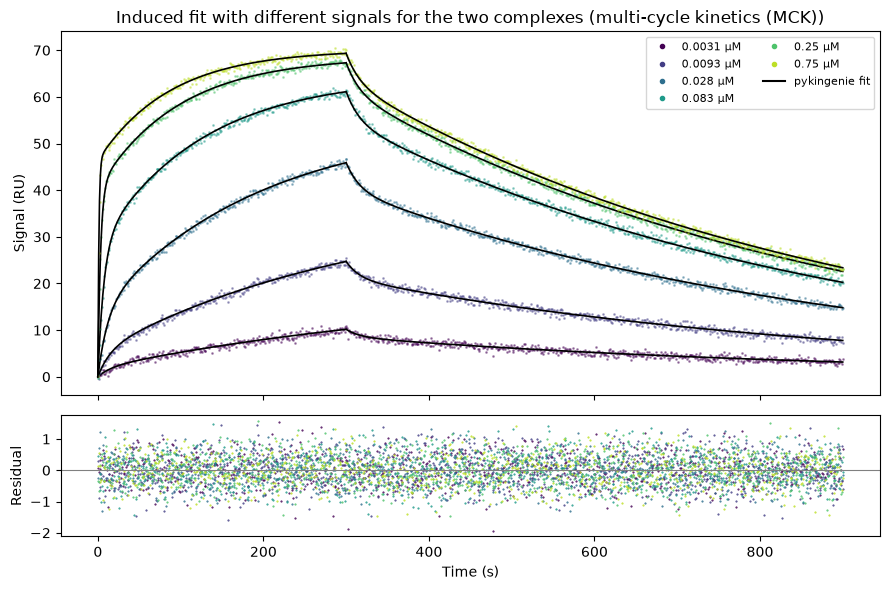

In [7]:
fig = plot_fit(data, fitter, concs, 'Induced fit with different signals for the two complexes (multi-cycle kinetics (MCK))')